# ML Assignment 2 – Email Spam Classification
**Problem Statement:** Classify the email using the binary classification method. Email Spam detection has two states: a) Normal State – Not Spam, b) Abnormal State – Spam. Use K-Nearest Neighbors and Support Vector Machine for classification. Analyze their performance.

Dataset: `emails.csv` (5172 emails, 3000 word-count columns, last column `Prediction`: 1 = spam, 0 = not spam).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('emails.csv')
print(df.shape)
df.head()

(5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


Missing values: 0
Prediction
0    3672
1    1500
Name: count, dtype: int64


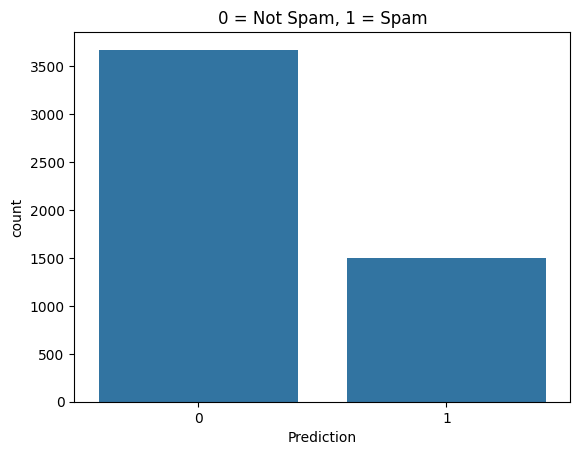

In [3]:
print('Missing values:', df.isnull().sum().sum())
print(df['Prediction'].value_counts())
sns.countplot(x='Prediction', data=df)
plt.title('0 = Not Spam, 1 = Spam')
plt.show()

In [4]:
X = df.drop(columns=['Email No.', 'Prediction'])
y = df['Prediction']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## K-Nearest Neighbors

KNN Accuracy: 0.8338164251207729
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



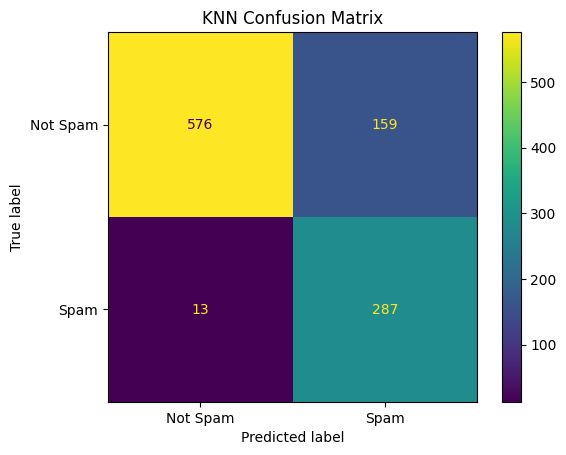

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
y_pred_knn = knn.predict(X_test_s)
print('KNN Accuracy:', accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn, target_names=['Not Spam', 'Spam']))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn), display_labels=['Not Spam', 'Spam']).plot()
plt.title('KNN Confusion Matrix'); plt.show()

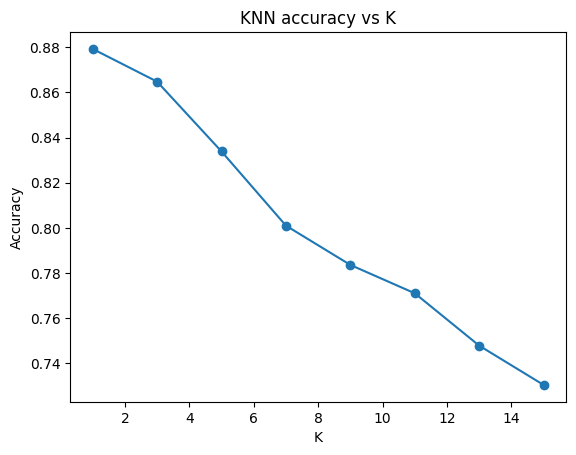

In [6]:
# Choosing the best K
scores = []
for k in range(1, 16, 2):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    scores.append(accuracy_score(y_test, m.predict(X_test_s)))
plt.plot(range(1, 16, 2), scores, marker='o')
plt.xlabel('K'); plt.ylabel('Accuracy'); plt.title('KNN accuracy vs K'); plt.show()

## Support Vector Machine

SVM Accuracy: 0.9671497584541063
              precision    recall  f1-score   support

    Not Spam       0.98      0.97      0.98       735
        Spam       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035



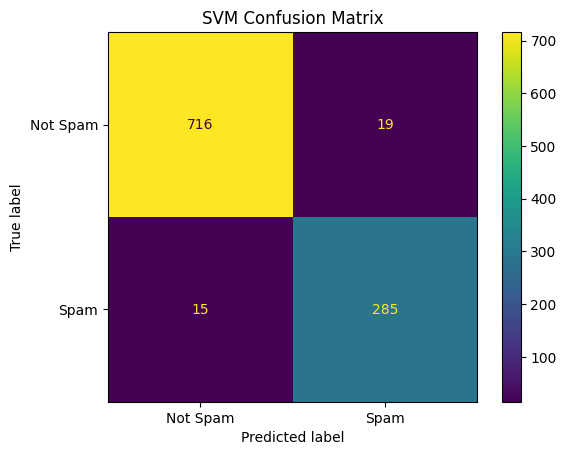

In [7]:
svm = SVC(kernel='linear', C=1.0)
svm.fit(X_train, y_train)   # linear SVM works well on raw word counts
y_pred_svm = svm.predict(X_test)
print('SVM Accuracy:', accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm, target_names=['Not Spam', 'Spam']))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svm), display_labels=['Not Spam', 'Spam']).plot()
plt.title('SVM Confusion Matrix'); plt.show()

## Performance comparison

In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score
comp = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [accuracy_score(y_test, y_pred_knn), accuracy_score(y_test, y_pred_svm)],
    'Precision': [precision_score(y_test, y_pred_knn), precision_score(y_test, y_pred_svm)],
    'Recall': [recall_score(y_test, y_pred_knn), recall_score(y_test, y_pred_svm)],
    'F1': [f1_score(y_test, y_pred_knn), f1_score(y_test, y_pred_svm)],
})
comp

,Model,Accuracy,Precision,Recall,F1
0,KNN,0.833816,0.643498,0.956667,0.769437
1,SVM,0.967150,0.937500,0.950000,0.943709


**Conclusion:** SVM performs better than KNN on this high-dimensional (3000 features) text data. KNN suffers from the curse of dimensionality, while SVM finds an optimal separating hyperplane.